# Benchmark lab

Try configs and models interactively, then promote the good ones to a YAML benchmark.

This uses the project's own code — `ml/data.py` (features), `ml/splits.py`, `ml/models.py`,
`ml/metrics.py`, `ml/benchmark.py` — so a result here matches `pixi run benchmark`.
The only difference: nothing is logged to MLflow until you save a config and run it from
the terminal (last section).

**Before you start:** kernel = `.pixi/envs/default/bin/python`, and `pixi run build` has
run. The data is loaded once (cell 2); re-run only the cells below it while experimenting.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                 # the warehouse's staging views read raw files by paths relative to the repo root
sys.path.insert(0, str(ROOT))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve

from ml import benchmark, data, models, splits
from ml.metrics import score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

## 1. Load the data (once — takes ~20 s)

One row per region per 6-hour block, every feature, years with weather. The label `y`
and the onset flag are added per threshold later, so changing the threshold doesn't reload.

In [2]:
YEARS = [2024, 2025]          # years with HRRR weather downloaded (add 2020-2023 once fetched)
BASE = data.load(None, YEARS)
print(f"{len(BASE):,} region-blocks, {BASE.region_fips.nunique()} regions, {BASE.block_start.min():%Y-%m-%d} → {BASE.block_start.max():%Y-%m-%d}")

605,789 region-blocks, 216 regions, 2024-01-01 → 2025-12-31


## 2. What you can combine

Feature groups (from `ml/data.py`) — combine with `+`, remove with `-`, e.g.
`"weather+place-canopy"`. Models (from `ml/models.py`) and their hyperparameters go in
`params`; a list means "try each value".

In [3]:
for name, cols in data.FEATURE_GROUPS.items():
    print(f"{name:8s} ({len(cols):2d}): {', '.join(cols)}")
print("\nmodels:", ", ".join(sorted(models.REGISTRY)))

weather  (17): gust_max_ms, wind10_max_ms, wind850_max_ms, shear_0_6km_max_ms, cape_max_jkg, precip_sum_mm, precip_max_1h_mm, temp_min_c, temp_mean_c, freezing_level_min_m, icing_hours, hail_hours, wind_x_precip, wind_squared, shear_x_cape, month, block_hour_utc
place    ( 6): log_customers, housing_per_km2, share_homes_pre1960, median_year_built, canopy_mean_pct, canopy_dense_share
canopy   ( 2): canopy_mean_pct, canopy_dense_share
history  ( 5): hist_hours_out_per_customer, hist_events_per_year, hist_storm_hit_rate, hist_quiet_event_rate, hist_repeat_7d_share
recent   ( 2): prev_block_pct_out, max_pct_out_prev_24h

models: climatology, hgb, lightgbm, logistic, prior, random_forest, xgboost


## 3. Your experiment

Same shape as a YAML config in `ml/benchmarks/`. Keep it small while exploring — a
`county` split fits 5 models per run, so it's ~5x slower than `time`.

In [4]:
CONFIG = {
    "name": "lab",
    "data": {"threshold_pct": [5], "years": YEARS, "train_on": ["all"]},
    "rank_by": "onset_pr_auc",
    "splits": [
        {"kind": "time", "train_years": [2024], "test_years": [2025]},
        # {"kind": "county", "folds": 5},
    ],
    "features": ["weather", "weather+place", "weather+place-canopy"],
    "models": [
        {"name": "climatology"},
        {"name": "xgboost", "params": {"n_estimators": 400, "learning_rate": 0.03, "max_depth": [4, 6],
                                       "min_child_weight": 5, "subsample": 0.8, "colsample_bytree": 0.8}},
    ],
}
runs = benchmark.plan(CONFIG)
print(f"{len(runs)} runs")
for r in runs:
    print(f"  >={r['threshold_pct']}% {r['train_on']:6s} {benchmark.split_label(r['split'])[:30]:30s} "
          f"{r['model']:12s} {r['features']:28s} {r['params']}")

7 runs
  >=5% all    time(train_years=[2024],test_y climatology  -                            {}
  >=5% all    time(train_years=[2024],test_y xgboost      weather                      {'n_estimators': 400, 'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}
  >=5% all    time(train_years=[2024],test_y xgboost      weather                      {'n_estimators': 400, 'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}
  >=5% all    time(train_years=[2024],test_y xgboost      weather+place                {'n_estimators': 400, 'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}
  >=5% all    time(train_years=[2024],test_y xgboost      weather+place                {'n_estimators': 400, 'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}
  >=5% all    time(train_years=[2024],test_y xg

## 4. Run it

In [5]:
labeled = {t: data.label(BASE, t) for t in {r["threshold_pct"] for r in runs}}
rows = []
for i, run in enumerate(runs, 1):
    scores = benchmark.evaluate(labeled[run["threshold_pct"]], run)
    rows.append({"threshold": run["threshold_pct"], "train_on": run["train_on"],
                 "split": run["split"]["kind"], "model": run["model"], "features": run["features"],
                 "params": str(run["params"]), **scores})
    print(f"[{i}/{len(runs)}] {run['model']:12s} {run['features']:28s} onset PR-AUC {scores['onset_pr_auc']:.3f} "
          f"({scores['onset_pr_auc_lift']:.1f}x)  all {scores['pr_auc']:.3f}  {scores['fit_seconds']:.0f}s")

RESULTS = pd.DataFrame(rows)
show = ["threshold", "train_on", "split", "model", "features", "params", "onset_pr_auc", "onset_pr_auc_lift",
        "onset_precision_top1", "onset_recall_top1", "pr_auc", "roc_auc", "brier", "fit_seconds"]
RESULTS[show].sort_values(["threshold", "split", "onset_pr_auc"], ascending=[True, True, False]).round(4)

[1/7] climatology  -                            onset PR-AUC 0.008 (1.5x)  all 0.014  0s
[2/7] xgboost      weather                      onset PR-AUC 0.057 (10.7x)  all 0.057  3s
[3/7] xgboost      weather                      onset PR-AUC 0.050 (9.3x)  all 0.052  4s
[4/7] xgboost      weather+place                onset PR-AUC 0.068 (12.8x)  all 0.073  3s
[5/7] xgboost      weather+place                onset PR-AUC 0.059 (11.2x)  all 0.068  4s
[6/7] xgboost      weather+place-canopy         onset PR-AUC 0.068 (12.8x)  all 0.074  3s
[7/7] xgboost      weather+place-canopy         onset PR-AUC 0.062 (11.7x)  all 0.069  3s


,threshold,train_on,split,model,features,params,onset_pr_auc,onset_pr_auc_lift,onset_precision_top1,onset_recall_top1,pr_auc,roc_auc,brier,fit_seconds
5,5,all,time,xgboost,weather+place-canopy,"{'n_estimators': 400, 'learning_rate': 0.03, '...",0.0682,12.8388,0.1140,0.2145,0.0735,0.7659,0.0095,2.8221
3,5,all,time,xgboost,weather+place,"{'n_estimators': 400, 'learning_rate': 0.03, '...",0.0680,12.7946,0.1085,0.2042,0.0731,0.7681,0.0095,2.8962
6,5,all,time,xgboost,weather+place-canopy,"{'n_estimators': 400, 'learning_rate': 0.03, '...",0.0619,11.6533,0.1099,0.2069,0.0693,0.7642,0.0095,3.3998
4,5,all,time,xgboost,weather+place,"{'n_estimators': 400, 'learning_rate': 0.03, '...",0.0593,11.1676,0.1074,0.2021,0.0677,0.7650,0.0096,3.5697
1,5,all,time,xgboost,weather,"{'n_estimators': 400, 'learning_rate': 0.03, '...",0.0568,10.6906,0.1077,0.2028,0.0569,0.7206,0.0096,2.5762
2,5,all,time,xgboost,weather,"{'n_estimators': 400, 'learning_rate': 0.03, '...",0.0496,9.3278,0.0993,0.1869,0.0519,0.7116,0.0096,3.5104
0,5,all,time,climatology,-,{},0.0080,1.5132,0.0180,0.0381,0.0145,0.5944,0.0099,0.3166


## 5. Compare

PR-AUC on new outages for every run. The dotted line is no skill (the onset event rate).

/var/folders/xh/l_wmyqk97tn2jq0mdftpyrgm0000gn/T/ipykernel_42407/3767143119.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


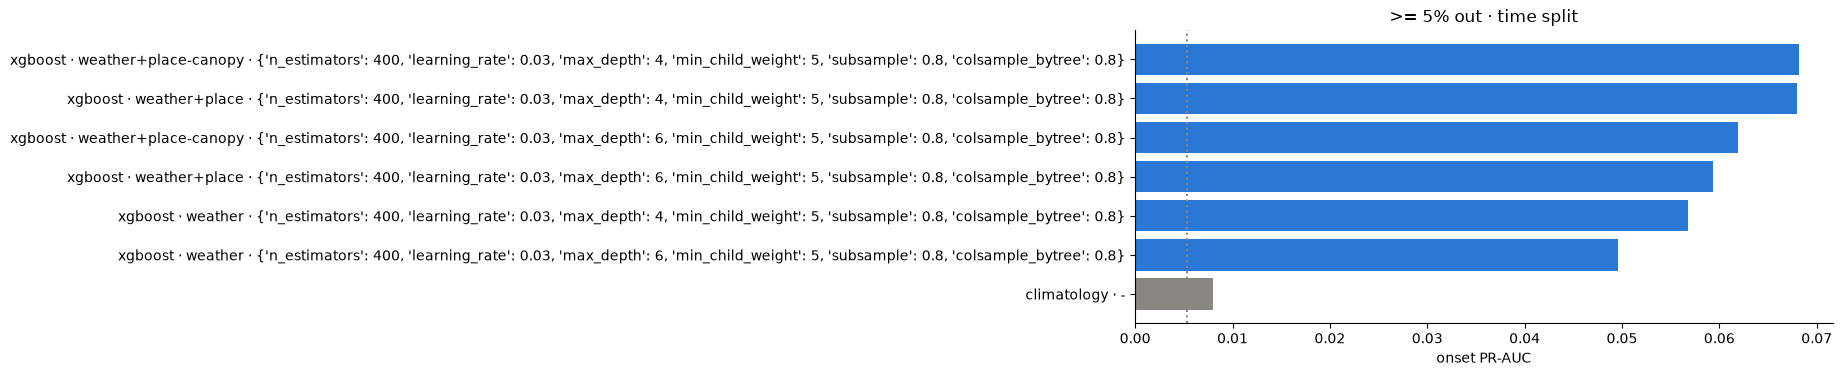

In [6]:
for (thr, split), g in RESULTS.groupby(["threshold", "split"]):
    g = g.sort_values("onset_pr_auc")
    labels = g.model + " · " + g.features + np.where(g.params != "{}", " · " + g.params, "")
    fig, ax = plt.subplots(figsize=(9, 0.4 * len(g) + 1))
    ax.barh(labels, g.onset_pr_auc, color=np.where(g.model.isin(benchmark.BASELINES), "#898781", "#2a78d6"))
    ax.axvline(g.onset_event_rate.iloc[0], ls=":", c="#898781")
    ax.set_xlabel("onset PR-AUC")
    ax.set_title(f">= {thr}% out · {split} split")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

## 6. Look inside one model

Trains one model on the first year and predicts the last, then shows:
- the **precision–recall curve**, all blocks vs. new outages — where the gap comes from
- **calibration** — when it says 10%, does it happen ~10% of the time?
- which features it **uses** (built-in importance; see `export_app_data.py` for permutation importance)

In [7]:
INSPECT = {"model": "xgboost", "features": "weather+place+history+recent", "threshold_pct": 5,
           "params": {"n_estimators": 400, "learning_rate": 0.03, "max_depth": 6, "min_child_weight": 5,
                      "subsample": 0.8, "colsample_bytree": 0.8}}

df = data.label(BASE, INSPECT["threshold_pct"])
cols = data.resolve_features(INSPECT["features"])
[(_, tr, te)] = list(splits.make_splits(df, "time", train_years=[min(YEARS)], test_years=[max(YEARS)]))
start = time.time()
model = models.build(INSPECT["model"], INSPECT["params"]).fit(df.iloc[tr][cols], df.iloc[tr]["y"])
test = df.iloc[te].assign(prob=model.predict_proba(df.iloc[te][cols])[:, 1])
print(f"trained in {time.time() - start:.0f}s")
pd.DataFrame({"all blocks": score(test.y, test.prob), "new outages": score(test.y[test.is_onset], test.prob[test.is_onset])}).round(4)

trained in 4s


,all blocks,new outages
pr_auc,0.3840,0.0872
pr_auc_lift,38.6946,16.4056
roc_auc,0.9049,0.8313
brier,0.0075,0.0050
log_loss,0.0344,0.0274
precision_top1,0.4688,0.1279
recall_top1,0.4726,0.2408
event_rate,0.0099,0.0053
n_test,290002.0000,271927.0000
n_events,2878.0000,1445.0000


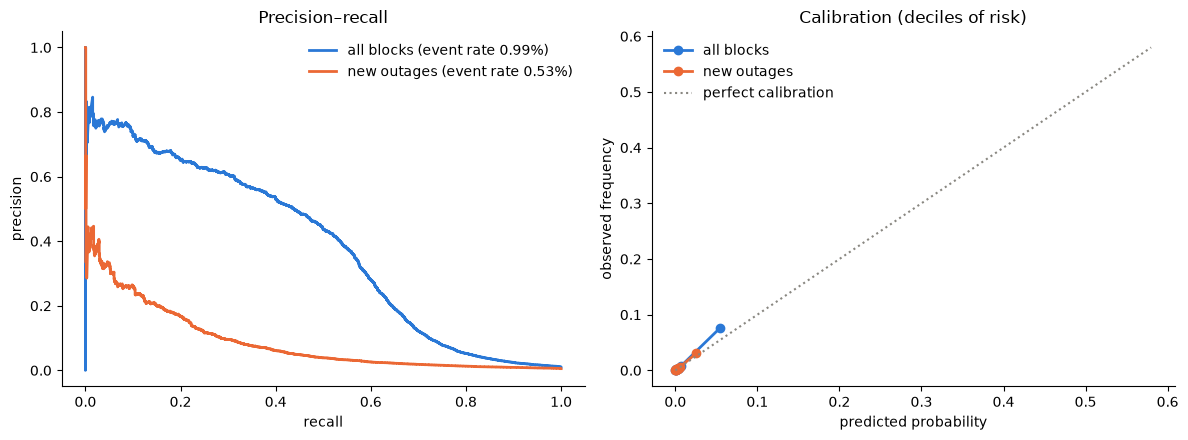

In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5))
for name, sub, color in [("all blocks", test, "#2a78d6"), ("new outages", test[test.is_onset], "#eb6834")]:
    p, r, _ = precision_recall_curve(sub.y, sub.prob)
    a.plot(r, p, color=color, lw=2, label=f"{name} (event rate {sub.y.mean():.2%})")
    frac, mean_pred = calibration_curve(sub.y, sub.prob, n_bins=10, strategy="quantile")
    b.plot(mean_pred, frac, "o-", color=color, lw=2, label=name)
a.set(xlabel="recall", ylabel="precision", title="Precision–recall")
lim = test.prob.quantile(0.999)
b.plot([0, lim], [0, lim], ":", c="#898781", label="perfect calibration")
b.set(xlabel="predicted probability", ylabel="observed frequency", title="Calibration (deciles of risk)")
for ax in (a, b):
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

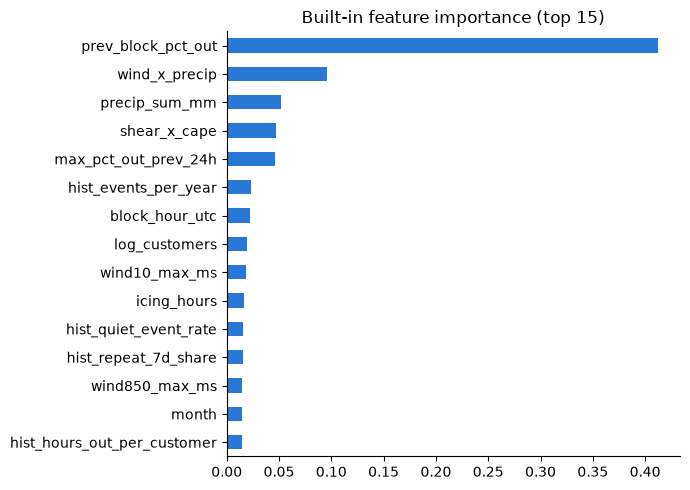

In [9]:
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=cols).sort_values().tail(15)
    ax = imp.plot.barh(figsize=(7, 5), color="#2a78d6", title="Built-in feature importance (top 15)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

### Where does it miss?

New outages the model ranked low — read their weather and place. Misses that share a
pattern are your next feature idea.

In [10]:
misses = test[test.is_onset & (test.y == 1)].sort_values("prob").head(15)
misses[["region", "block_start", "peak_pct_out", "prob", "gust_max_ms", "cape_max_jkg", "precip_sum_mm",
        "storm_reports", "canopy_mean_pct", "customers"]].round(3)

/var/folders/xh/l_wmyqk97tn2jq0mdftpyrgm0000gn/T/ipykernel_42407/1875577449.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "storm_reports", "canopy_mean_pct", "customers"]].round(3)


,region,block_start,peak_pct_out,prob,gust_max_ms,cape_max_jkg,precip_sum_mm,storm_reports,canopy_mean_pct,customers
184587,St. Charles,2025-02-21 00:00:00,5.098,0.0,5.1,0.0,0.0,0,26.75,181803.0
514206,Callaway,2025-12-14 18:00:00,5.958,0.0,4.6,0.0,0.0,0,32.63,28884.0
504479,Cole,2025-01-31 12:00:00,7.419,0.0,10.6,30.0,0.0,0,31.40,39963.0
205102,Vermilion,2025-10-02 00:00:00,10.996,0.0,8.1,0.0,0.0,0,8.15,46373.0
384860,Massac,2025-06-15 12:00:00,8.893,0.0,1.9,1540.0,0.0,0,27.15,8175.0
55350,Franklin,2025-04-28 00:00:00,8.296,0.0,8.7,0.0,0.0,0,43.19,46672.0
331028,Ogle,2025-02-17 12:00:00,5.456,0.0,10.3,0.0,0.0,1,8.03,42029.0
515946,Scott,2025-02-28 06:00:00,16.135,0.0,8.4,0.0,0.0,0,14.96,2163.0
161861,Cape Girardeau,2025-01-22 00:00:00,7.830,0.0,6.0,0.0,0.0,0,25.56,34407.0
514244,Callaway,2025-12-24 12:00:00,5.962,0.0,7.7,0.0,0.0,0,32.63,28884.0


## 7. Promote it to a real benchmark

Saves `CONFIG` as YAML. Then run it from the terminal — that logs every run to MLflow and
writes `ml/results/benchmark_<name>.csv` + a leaderboard:

```bash
pixi run benchmark ml/benchmarks/<name>.yaml
```

In [11]:
path = ROOT / "ml" / "benchmarks" / f"{CONFIG['name']}.yaml"
path.write_text(yaml.safe_dump(CONFIG, sort_keys=False))
print(f"saved {path.relative_to(ROOT)} — run: pixi run benchmark {path.relative_to(ROOT)}")

saved ml/benchmarks/lab.yaml — run: pixi run benchmark ml/benchmarks/lab.yaml
